# 任务 2：让 CLIP 配对图片和文字

用 OpenAI 官方开源实现 + 公开预训练权重 **RN50**（题目推荐的最小模型），只做推理不训练。

实验材料：4 张内容差异大的公开图片（Unsplash 免费图源，来源在下面逐张标注），每张配一句简短英文描述。流程：提取两类特征 → 打印形状 → L2 归一化 → 余弦相似度矩阵 → 热力图 → 检查配对 → 故意加错误描述观察 CLIP 能否识破。


In [1]:
import os
import torch
import clip
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)
model, preprocess = clip.load("RN50", device=device)
print("RN50 loaded")


device: cuda
RN50 loaded


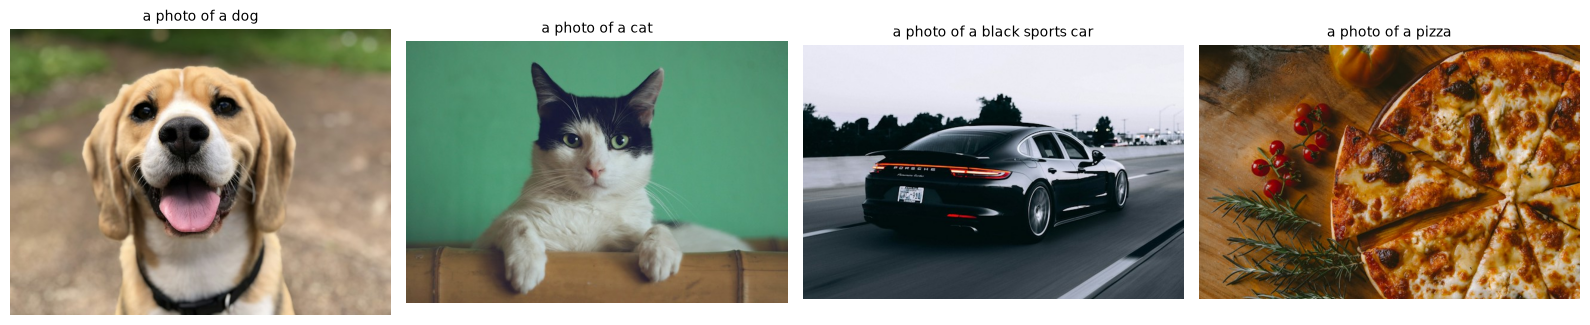

In [2]:
names = ["dog", "cat", "car", "pizza"]
texts = [
    "a photo of a dog",
    "a photo of a cat",
    "a photo of a black sports car",
    "a photo of a pizza",
]
paths = [f"images/{n}.jpg" for n in names]

# 图片来源（Unsplash 免费图源，2026-10 下载）：
# dog:   https://images.unsplash.com/photo-1543466835-00a7907e9de1
# cat:   https://images.unsplash.com/photo-1514888286974-6c03e2ca1dba
# car:   https://images.unsplash.com/photo-1503376780353-7e6692767b70
# pizza: https://images.unsplash.com/photo-1513104890138-7c749659a591

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, p, t in zip(axes, paths, texts):
    ax.imshow(Image.open(p))
    ax.set_title(t, fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()


In [3]:
image_inputs = torch.stack([preprocess(Image.open(p).convert("RGB")) for p in paths]).to(device)
text_inputs = clip.tokenize(texts).to(device)

with torch.no_grad():
    img_feat = model.encode_image(image_inputs)   # (4, 1024)
    txt_feat = model.encode_text(text_inputs)     # (4, 1024)

print("image features:", tuple(img_feat.shape))
print("text features:", tuple(txt_feat.shape))


image features: (4, 1024)
text features: (4, 1024)


## L2 归一化 + 余弦相似度

两个编码器的输出已经投影到**同一个 1024 维空间**，所以能直接算相似度。计算前各自做 L2 归一化（向量除以自己的长度），归一化之后的点积就等于余弦相似度——只看方向、不看长度，公平比较。


In [4]:
img_feat = img_feat / img_feat.norm(dim=-1, keepdim=True)
txt_feat = txt_feat / txt_feat.norm(dim=-1, keepdim=True)

sim = (img_feat @ txt_feat.T).cpu().numpy()   # (4, 4) 余弦相似度矩阵
print("cosine similarity matrix (4x4):")
print(np.round(sim, 3))


cosine similarity matrix (4x4):
[[0.238 0.157 0.111 0.153]
 [0.197 0.25  0.151 0.181]
 [0.147 0.136 0.2   0.131]
 [0.136 0.142 0.11  0.229]]


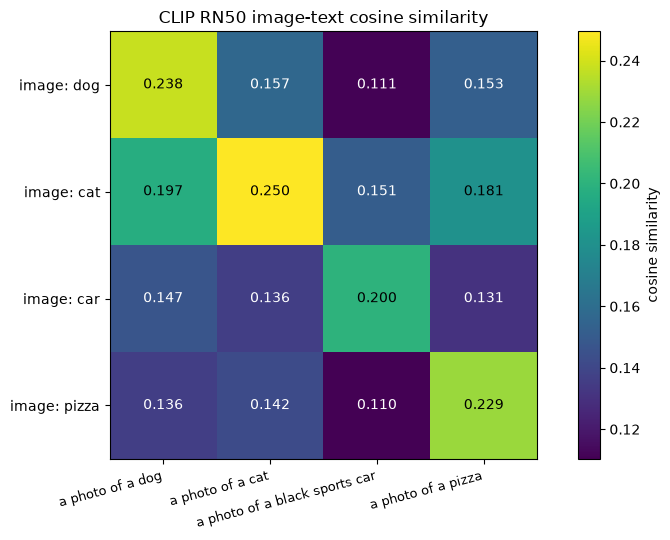

saved: clip-similarity.png
each row argmax: [0, 1, 2, 3]
diagonal = each image matches its own caption: True


In [5]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))
im = ax.imshow(sim, cmap="viridis", vmin=sim.min(), vmax=sim.max())
ax.set_xticks(range(4))
ax.set_xticklabels(texts, rotation=15, ha="right", fontsize=9)
ax.set_yticks(range(4))
ax.set_yticklabels([f"image: {n}" for n in names])
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{sim[i, j]:.3f}", ha="center", va="center",
                color="white" if sim[i, j] < (sim.max() + sim.min()) / 2 else "black")
fig.colorbar(im, label="cosine similarity")
ax.set_title("CLIP RN50 image-text cosine similarity")
plt.tight_layout()
plt.savefig("clip-similarity.png", dpi=150, bbox_inches="tight")
plt.show()
print("saved: clip-similarity.png")

print("each row argmax:", [int(sim[i].argmax()) for i in range(4)])
print("diagonal = each image matches its own caption:", all(sim[i].argmax() == i for i in range(4)))


## 配对结果分析

每行的最大值都落在对角线上（argmax = 0,1,2,3），四张图全部配对成功。值得注意：

1. **相似度绝对值不高**（对角线 0.20~0.25）。别慌——CLIP 的余弦相似度普遍压在低位，判断配对看**相对大小**，不看绝对值。对角线比同行的非对角高出一大截（0.05~0.10 的差距），配对非常确凿；
2. **cat 和 dog 互相"沾光"**：image:dog 对 "a photo of a cat" 的相似度（0.157）不算最低，image:cat 对 dog 描述也偏high——猫狗都是动物、构图又都是宠物特写，特征空间里本来就挨得近。最"孤立"的是 pizza，和其他三类的交叉相似度都垫底，食物和前三类差异实在太大；
3. "a photo of a black sports car" 描述里加了颜色和类别词，car 一行对角线照样最高——描述具体一点不干扰正确配对，反而（后面会看到）是识别错误描述的依据。


## 故意喂错误描述

构造一句和图片很相似、但关键内容错误的描述，看 CLIP 能不能分辨。三组错误，分别错在**颜色、数量、动作**：

- dog 图："a photo of a **cat**"（类别错误）+ "**three** dogs"（数量错误，实际 1 只）
- car 图："a **red** sports car"（颜色错误，实际黑色）+ "a parked sports car"（动作错误，实际行驶中）
- pizza 图："a pizza **cut into slices**"（状态错误，实际是完整未切的一整张）+ "a **cake**"（类别错误）

把正确描述和错误描述放进同一组文本里，看每张图选谁。


In [6]:
probes = {
    "dog": ["a photo of a dog", "a photo of a cat",
            "a photo of three dogs", "a photo of a dog with a collar"],
    "car": ["a photo of a black sports car", "a photo of a red sports car",
            "a photo of a parked sports car", "a photo of a sports car driving on a highway"],
    "pizza": ["a photo of a whole cheese pizza", "a photo of a pepperoni pizza",
              "a photo of a pizza cut into slices", "a photo of a cake"],
}

for img_name, cand in probes.items():
    i = names.index(img_name)
    t = clip.tokenize(cand).to(device)
    with torch.no_grad():
        tf = model.encode_text(t)
    tf = tf / tf.norm(dim=-1, keepdim=True)
    sims = (img_feat[i:i+1] @ tf.T).cpu().numpy()[0]   # 这张图对每组描述的相似度
    order = np.argsort(-sims)
    print(f"--- image: {img_name} ---")
    for rank, k in enumerate(order):
        tag = " <== best" if rank == 0 else ""
        print(f"  {sims[k]:.4f}  {cand[k]}{tag}")


--- image: dog ---
  0.2515  a photo of a dog with a collar <== best
  0.2379  a photo of a dog
  0.1799  a photo of three dogs
  0.1567  a photo of a cat
--- image: car ---
  0.2126  a photo of a sports car driving on a highway <== best
  0.2054  a photo of a parked sports car
  0.2001  a photo of a black sports car
  0.1624  a photo of a red sports car
--- image: pizza ---
  0.2163  a photo of a whole cheese pizza <== best
  0.2162  a photo of a pizza cut into slices
  0.2085  a photo of a pepperoni pizza
  0.1613  a photo of a cake


## 错误描述实验观察

**类别错误（dog → "cat"）**：识别成功。"a photo of a dog"（0.2379）明显高于 "a photo of a cat"（0.1567）——猫狗在特征空间里虽近，CLIP 分得清。

**细节描述反而加分（"a dog with a collar"）**：排第一的不是我写的"正确"描述，而是"戴项圈的狗"（0.2515 > 0.2379）——图里的比格犬确实戴着黑项圈。CLIP 抓住了这个视觉细节，说明它的图文匹配比笼统的类别词更细腻。也给了一个提醒："正确描述"是谁，取决于你写得多具体。

**数量错误（"three dogs"）**：0.1799，比正确描述低不少，排倒数第二。CLIP 没有被"dogs"复数完全骗过，但也别高估它——论文 7.1 节自己承认 CLIP 在计数任务上很弱，这里的差距更多来自句子整体语义，不是真会数数。

**颜色错误（"red sports car" vs 黑色实车）**：识别成功。"black"（0.2001）比 "red"（0.1624）高出一截——CLIP 对高频出现的颜色词有分辨力。

**动作/状态错误（"parked" vs 行驶中）**：这是最有意思的一组。"driving on a highway"（0.2126）最高，"black sports car"（0.2001）第三，"parked"（0.2054）紧咬第二——三者差距只有 0.01 量级。CLIP 抓住了"车在路上"的整体氛围（所以 driving 最高），但对"行驶还是停放"这种状态差异几乎没有分辨力， parked 和 driving 的得分几乎并列。动作类细粒度差异是它的盲区。

**pizza 组**："whole cheese pizza"（0.2163）和 "cut into slices"（0.2162）几乎完全并列——差距只有 0.0001，CLIP 完全分不清"整张 vs 切片"这种状态。"pepperoni"（0.2085）也没有被明显压下去，说明它对披萨配料并不较真。唯一的类别错误 "cake"（0.1613）被明确排最后——图里连甜点都没有。

**总结：CLIP 的敏感度排序大致是 类别 >> 细节佐证 > 颜色 > 数量/状态**。语义层面的错误它能识破，越往细粒度走（数数、动作状态、切片与否）越不可靠——而且它的相似度普遍挤在 0.15~0.25 的窄区间里，判断配对永远看相对排名，不看绝对值。这正好呼应阅读笔记第 8 问"CLIP 的局限"。
